# 03 - SWOT and HF-radar directional component comparison

This notebook computes and validates eastward and northward velocity components, current direction, and directional agreement between collocated SWOT-based currents and HF radar.

The workflow reuses complete native SWOT, coarsened SWOT, and HF-radar matched triplets from `data/processed/swot_hfradar_matches`. Direction errors are treated as circular quantities, and observations below the minimum speed threshold are excluded because their direction is unstable.

## 1. Set Up Environment and Project Paths

Configure the scientific Python environment, project directories, plotting defaults, and reproducibility settings.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

try:
    import cartopy.crs as ccrs
except ImportError:
    ccrs = None

REPO = Path.cwd().resolve().parent
PROCESSED_DIR = REPO / 'data' / 'processed' / 'swot_hfradar_matches'
NATIVE_DIR = PROCESSED_DIR / 'swot_native_masked'
COARSE_DIR = PROCESSED_DIR / 'swot_coarsened_masked'
RADAR_DIR = PROCESSED_DIR / 'hfradar_swot_masked'
OUTPUT_DIR = REPO / 'data' / 'processed' / 'direction_component_comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_DIRECTION_SPEED = 0.05
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'font.size': 10,
    'axes.grid': True,
    'grid.color': 'lightgrey',
    'grid.linestyle': '--',
    'grid.linewidth': 0.5,
})

print(f'Repository: {REPO}')
print(f'Matched products directory: {PROCESSED_DIR}')
print(f'Output directory for tables: {OUTPUT_DIR}')
print(f'Minimum speed for direction: {MIN_DIRECTION_SPEED:.2f} m/s')

Repository: <repo>
Matched products directory: <repo>/data/processed/swot_hfradar_matches
Output directory for tables: <repo>/data/processed/direction_component_comparison
Minimum speed for direction: 0.05 m/s


## 2. Load SWOT and HF Radar Datasets

Open the processed matched products from notebook 02 and standardise access to the component variables.

In [2]:
def indexed_files(directory, prefix):
    indexed = {}
    for path in sorted(directory.glob(f'{prefix}_*.nc')):
        with xr.open_dataset(path) as dataset:
            if 'cycle' in dataset.attrs and 'pass' in dataset.attrs:
                indexed[(int(dataset.attrs['cycle']), int(dataset.attrs['pass']))] = path
    return indexed

native_files = indexed_files(NATIVE_DIR, 'swot_native_masked')
coarse_files = indexed_files(COARSE_DIR, 'swot_coarsened_masked')
radar_files = indexed_files(RADAR_DIR, 'hfradar_swot_masked')
required = set(native_files) & set(coarse_files) & set(radar_files)
missing_native = sorted((set(coarse_files) & set(radar_files)) - set(native_files))
missing_coarse = sorted((set(native_files) & set(radar_files)) - set(coarse_files))
missing_radar = sorted((set(native_files) & set(coarse_files)) - set(radar_files))
if missing_native or missing_coarse or missing_radar:
    print(f'Excluded incomplete events: native={missing_native}, coarse={missing_coarse}, radar={missing_radar}')
if not required:
    raise FileNotFoundError(
        f'No complete SWOT/HF-radar triplets found in {NATIVE_DIR}, {COARSE_DIR}, and {RADAR_DIR}.'
    )

print(f'Complete SWOT/HF-radar events available: {len(required)}')
print(
    f'Products indexed: native={len(native_files)}, '
    f'coarse={len(coarse_files)}, radar={len(radar_files)}'
)

Complete SWOT/HF-radar events available: 33
Products indexed: native=33, coarse=33, radar=33


## 3. Harmonize Coordinates, Time, and Units

The matched products use a common 6 km latitude-longitude grid. Components are treated as metres per second, timestamps are retained as UTC-like metadata strings, and the final comparison mask is applied consistently.

In [3]:
def read_components(event_id):
    with xr.open_dataset(native_files[event_id]) as dataset:
        native_u = dataset['ugos_masked'].values.astype(float)
        native_v = dataset['vgos_masked'].values.astype(float)

    with xr.open_dataset(coarse_files[event_id]) as dataset:
        final_mask = dataset['comparison_mask'].values.astype(bool)
        swot_time = pd.to_datetime(dataset.attrs['swot_time'], utc=True)
        latitude = dataset['latitude'].values.astype(float)
        longitude = dataset['longitude'].values.astype(float)
        latitude_grid, longitude_grid = np.meshgrid(latitude, longitude, indexing='ij')
        swot_u = dataset['ugos_coarsened_raw'].values.astype(float)
        swot_v = dataset['vgos_coarsened_raw'].values.astype(float)

    with xr.open_dataset(radar_files[event_id]) as dataset:
        radar_u = dataset['ewct_raw'].values.astype(float)
        radar_v = dataset['nsct_raw'].values.astype(float)

    components = {
        'SWOT': (swot_u, swot_v),
        'HF radar': (radar_u, radar_v),
    }
    valid = final_mask.copy()
    for component_u, component_v in components.values():
        valid &= np.isfinite(component_u) & np.isfinite(component_v)

    return {
        'event_id': event_id,
        'time': swot_time,
        'latitude': latitude_grid,
        'longitude': longitude_grid,
        'components': components,
        'native_components': (native_u, native_v),
        'valid': valid,
    }

records = [read_components(event_id) for event_id in sorted(required)]
print(f'Loaded {len(records)} collocated SWOT/HF-radar directional records')
print(f'Common grid shape: {records[0]["valid"].shape}')

Loaded 33 collocated SWOT/HF-radar directional records
Common grid shape: (75, 150)


## 4. Derive HF Radar Directional Velocity Components

HF-radar eastward and northward components are taken from `ewct_raw` and `nsct_raw`. Direction is measured anticlockwise from east, consistent with `atan2(v, u)`.

In [4]:
def direction_degrees(u, v):
    return (np.degrees(np.arctan2(v, u)) + 360.0) % 360.0


def wrapped_direction_error(model_direction, reference_direction):
    return (model_direction - reference_direction + 180.0) % 360.0 - 180.0


def direction_components(u, v):
    speed = np.hypot(u, v)
    direction = direction_degrees(u, v)
    return speed, direction

for record in records:
    record['speed'] = {}
    record['direction'] = {}
    for model_name, (component_u, component_v) in record['components'].items():
        speed, direction = direction_components(component_u, component_v)
        record['speed'][model_name] = speed
        record['direction'][model_name] = direction

print('Direction convention: 0 degrees = east, 90 degrees = north, 180 degrees = west, 270 degrees = south')
print('Angular errors are wrapped to the interval [-180, 180) degrees')

Direction convention: 0 degrees = east, 90 degrees = north, 180 degrees = west, 270 degrees = south
Angular errors are wrapped to the interval [-180, 180) degrees


## 5. Subset and Collocate SWOT With HF Radar Grids

The final filtered files already encode the valid spatial overlap. The code below applies an additional direction-specific speed threshold to paired SWOT and HF-radar vectors.

In [5]:
model_names = ['SWOT']

paired_direction_data = {
    model_name: {
        'model': [],
        'reference': [],
        'reference_speed': [],
        'time': [],
        'latitude': [],
        'longitude': [],
    }
    for model_name in model_names
}

for record in records:
    radar_direction = record['direction']['HF radar']
    radar_speed = record['speed']['HF radar']
    for model_name in model_names:
        direction_data = paired_direction_data[model_name]
        model_direction = record['direction'][model_name]
        model_speed = record['speed'][model_name]
        valid = (
            record['valid']
            & np.isfinite(model_direction)
            & np.isfinite(radar_direction)
            & (model_speed >= MIN_DIRECTION_SPEED)
            & (radar_speed >= MIN_DIRECTION_SPEED)
        )
        direction_data['model'].append(model_direction[valid])
        direction_data['reference'].append(radar_direction[valid])
        direction_data['reference_speed'].append(radar_speed[valid])
        direction_data['time'].append(np.full(valid.sum(), record['time'].tz_localize(None), dtype='datetime64[ns]'))
        direction_data['latitude'].append(record['latitude'][valid])
        direction_data['longitude'].append(record['longitude'][valid])

for model_name, direction_data in paired_direction_data.items():
    for key in direction_data:
        direction_data[key] = np.concatenate(direction_data[key])
    direction_data['error'] = wrapped_direction_error(direction_data['model'], direction_data['reference'])
    direction_data['absolute_error'] = np.abs(direction_data['error'])

print(f'Direction threshold applied to both model and HF radar speeds: {MIN_DIRECTION_SPEED:.2f} m/s')
for model_name in model_names:
    print(f'{model_name}: {paired_direction_data[model_name]["error"].size:,} valid directional pairs')

Direction threshold applied to both model and HF radar speeds: 0.05 m/s
SWOT: 6,216 valid directional pairs


## 6. Compute Agreement Metrics for Directional Components

Report component-wise bias, RMSE, correlation, and robust spread, together with circular direction-error metrics.

In [20]:
def component_metrics(model_name, direction_data):
    model_u, model_v = [], []
    radar_u, radar_v = [], []
    for record in records:
        model_component_u, model_component_v = record['components'][model_name]
        reference_component_u, reference_component_v = record['components']['HF radar']
        valid = (
            record['valid']
            & (record['speed'][model_name] >= MIN_DIRECTION_SPEED)
            & (record['speed']['HF radar'] >= MIN_DIRECTION_SPEED)
        )
        model_u.append(model_component_u[valid])
        model_v.append(model_component_v[valid])
        radar_u.append(reference_component_u[valid])
        radar_v.append(reference_component_v[valid])
    model_u = np.concatenate(model_u)
    model_v = np.concatenate(model_v)
    radar_u = np.concatenate(radar_u)
    radar_v = np.concatenate(radar_v)
    metrics = {}
    for component, model_values, reference_values in (
        ('u', model_u, radar_u),
        ('v', model_v, radar_v),
    ):
        difference = model_values - reference_values
        metrics[component] = {
            'bias': float(np.mean(difference)),
            'rmse': float(np.sqrt(np.mean(difference ** 2))),
            'correlation': float(np.corrcoef(model_values, reference_values)[0, 1]),
            'robust_spread': float(1.4826 * np.median(np.abs(difference - np.median(difference)))),
        }
    return metrics

metrics_rows = []
for model_name in model_names:
    direction_data = paired_direction_data[model_name]
    metrics = component_metrics(model_name, direction_data)
    metrics_rows.append({
        'dataset': model_name,
        'direction_bias_deg': float(np.mean(direction_data['error'])),
        'direction_mae_deg': float(np.mean(direction_data['absolute_error'])),
        'direction_rmse_deg': float(np.sqrt(np.mean(direction_data['error'] ** 2))),
        'direction_median_abs_deg': float(np.median(direction_data['absolute_error'])),
        'within_15_deg_pct': float(100 * np.mean(direction_data['absolute_error'] <= 15)),
        'within_30_deg_pct': float(100 * np.mean(direction_data['absolute_error'] <= 30)),
        'within_45_deg_pct': float(100 * np.mean(direction_data['absolute_error'] <= 45)),
        'u_bias_mps': metrics['u']['bias'],
        'u_rmse_mps': metrics['u']['rmse'],
        'u_correlation': metrics['u']['correlation'],
        'u_robust_spread_mps': metrics['u']['robust_spread'],
        'v_bias_mps': metrics['v']['bias'],
        'v_rmse_mps': metrics['v']['rmse'],
        'v_correlation': metrics['v']['correlation'],
        'v_robust_spread_mps': metrics['v']['robust_spread'],
    })

metrics_table = pd.DataFrame(metrics_rows).set_index('dataset')

Directional and component agreement metrics:
         direction_bias_deg  direction_mae_deg  direction_rmse_deg  direction_median_abs_deg  within_15_deg_pct  within_30_deg_pct  within_45_deg_pct  u_bias_mps  u_rmse_mps  u_correlation  u_robust_spread_mps  v_bias_mps  v_rmse_mps  v_correlation  v_robust_spread_mps
dataset                                                                                                                                                                                                                                                                      
SWOT                 1.9559            35.7983              55.462                    17.848            45.1577            63.9157            73.7773      0.0485      0.4401         0.7566               0.3551      -0.003      0.2456         0.8569                0.223


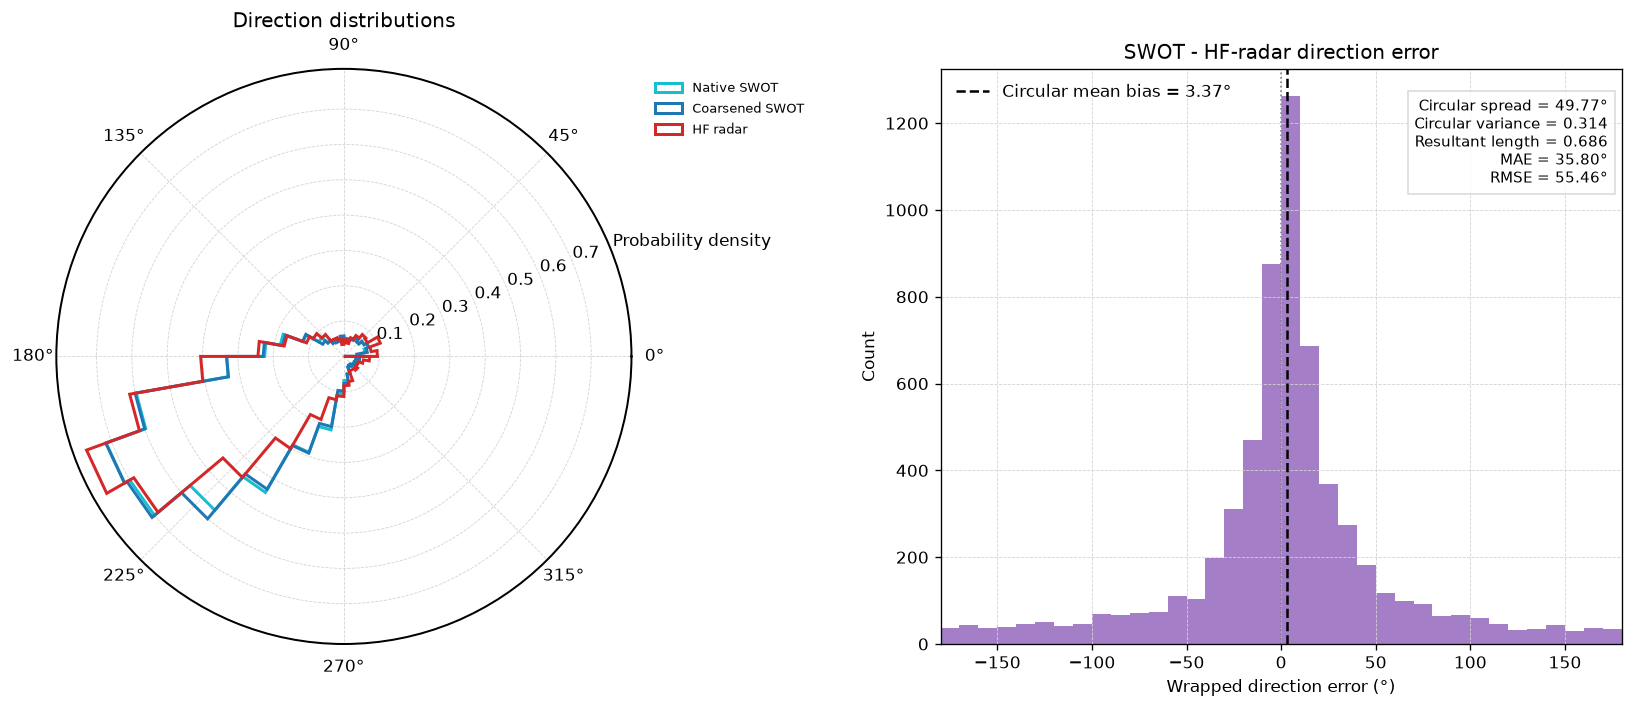

In [75]:
# Directional distribution and wrapped direction-error comparison

data = paired_direction_data['SWOT']
error_radians = np.radians(data['error'])
mean_sine = np.mean(np.sin(error_radians))
mean_cosine = np.mean(np.cos(error_radians))
resultant_length = float(np.hypot(mean_sine, mean_cosine))
circular_mean_bias = float(np.degrees(np.arctan2(mean_sine, mean_cosine)))
circular_spread = float(
    np.degrees(np.sqrt(-2.0 * np.log(resultant_length)))
) if resultant_length > 0 else np.nan
circular_variance = 1.0 - resultant_length

directional_mae = float(np.mean(data['absolute_error']))
directional_rmse = float(np.sqrt(np.mean(data['error'] ** 2)))

native_directions = []
for record in records:
    native_u, native_v = record['native_components']
    native_speed, native_direction = direction_components(native_u, native_v)
    native_valid = (
        np.isfinite(native_speed)
        & np.isfinite(native_direction)
        & (native_speed >= MIN_DIRECTION_SPEED)
    )
    native_directions.append(native_direction[native_valid])
native_directions = np.concatenate(native_directions)

figure = plt.figure(figsize=(14, 6))
polar_axis = figure.add_subplot(1, 2, 1, projection='polar')
error_axis = figure.add_subplot(1, 2, 2)

direction_bin_edges = np.linspace(0.0, 360.0, 37)

for label, direction, colour in (
    ('Native SWOT', native_directions, '#17becf'),
    ('Coarsened SWOT', data['model'], '#1f77b4'),
    ('HF radar', data['reference'], '#d62728'),
):
    polar_axis.hist(
        np.radians(direction),
        bins=np.radians(direction_bin_edges),
        histtype='step',
        density=True,
        linewidth=1.8,
        color=colour,
        label=label,
    )
polar_axis.set_theta_zero_location('E')
polar_axis.set_theta_direction(1)
polar_axis.set_title('Direction distributions')
polar_axis.set_ylabel('')
polar_axis.set_yticks(np.arange(0.1, 0.8, 0.1))
polar_axis.spines['polar'].set_visible(True)
polar_axis.spines['polar'].set_color('black')
polar_axis.spines['polar'].set_linewidth(1.2)
polar_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
polar_axis.annotate(
    'Probability density',
    xy=(np.radians(15), 0.8),
    xytext=(45, 20),
    textcoords='offset points',
    ha='center',
    va='bottom',
    fontsize=10,
    clip_on=False,
)
polar_axis.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False)

error_axis.hist(
    data['error'],
    bins=np.linspace(-180, 180, 37),
    color='#9467bd',
    alpha=0.85,
    edgecolor='none',
    linewidth=0,
)
error_axis.axvline(
    circular_mean_bias,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label=f'Circular mean bias = {circular_mean_bias:.2f}°',
)
error_axis.axvline(0, color='grey', linestyle=':', linewidth=1)
error_axis.text(
    0.98,
    0.95,
    f'Circular spread = {circular_spread:.2f}°\n'
    f'Circular variance = {circular_variance:.3f}\n'
    f'Resultant length = {resultant_length:.3f}\n'
    f'MAE = {directional_mae:.2f}°\n'
    f'RMSE = {directional_rmse:.2f}°',
    transform=error_axis.transAxes,
    ha='right',
    va='top',
    fontsize=9,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgrey'),
)
error_axis.set_xlim(-180, 180)
error_axis.set_title('SWOT - HF-radar direction error')
error_axis.set_xlabel('Wrapped direction error (°)')
error_axis.set_ylabel('Count')
error_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
error_axis.legend(frameon=False)

figure.tight_layout()
plt.show()

In [6]:
# Summary statistics for the SWOT-HF-radar directional comparison.

data = paired_direction_data['SWOT']
error_radians = np.radians(data['error'])
mean_sine = np.mean(np.sin(error_radians))
mean_cosine = np.mean(np.cos(error_radians))
resultant_length = float(np.hypot(mean_sine, mean_cosine))
circular_mean_bias = float(np.degrees(np.arctan2(mean_sine, mean_cosine)))
circular_variance = float(1.0 - resultant_length)
circular_spread = float(
    np.degrees(np.sqrt(-2.0 * np.log(resultant_length)))
) if resultant_length > 0 else np.nan

absolute_error = data['absolute_error']
directional_statistics = pd.DataFrame(
    {
        'Metric': [
            'Paired directional observations',
            'Circular mean bias',
            'Mean absolute directional error',
            'Directional RMSE',
            'Median absolute directional error',
            'Circular spread',
            'Circular variance',
            'Resultant length',
            'Within 15 degrees',
            'Within 30 degrees',
            'Within 45 degrees',
        ],
        'Value': [
            f'{data["error"].size:,}',
            f'{circular_mean_bias:.2f} degrees',
            f'{np.mean(absolute_error):.2f} degrees',
            f'{np.sqrt(np.mean(data["error"] ** 2)):.2f} degrees',
            f'{np.median(absolute_error):.2f} degrees',
            f'{circular_spread:.2f} degrees',
            f'{circular_variance:.3f}',
            f'{resultant_length:.3f}',
            f'{100 * np.mean(absolute_error <= 15):.1f}%',
            f'{100 * np.mean(absolute_error <= 30):.1f}%',
            f'{100 * np.mean(absolute_error <= 45):.1f}%',
        ],
        'Purpose': [
            'Nominal paired sample size',
            'Signed circular directional difference',
            'Typical absolute directional difference',
            'Directional error including larger deviations',
            'Robust absolute directional difference',
            'Circular dispersion of directional errors',
            'Circular dispersion measure, 0 to 1',
            'Concentration of directional errors, 0 to 1',
            'Fraction of pairs within 15 degrees',
            'Fraction of pairs within 30 degrees',
            'Fraction of pairs within 45 degrees',
        ],
    }
)

directional_statistics

,Metric,Value,Purpose
0,Paired directional observations,"6,216",Nominal paired sample size
1,Circular mean bias,3.37 degrees,Signed circular directional difference
2,Mean absolute directional error,35.80 degrees,Typical absolute directional difference
3,Directional RMSE,55.46 degrees,Directional error including larger deviations
4,Median absolute directional error,17.85 degrees,Robust absolute directional difference
5,Circular spread,49.77 degrees,Circular dispersion of directional errors
6,Circular variance,0.314,"Circular dispersion measure, 0 to 1"
7,Resultant length,0.686,"Concentration of directional errors, 0 to 1"
8,Within 15 degrees,45.2%,Fraction of pairs within 15 degrees
9,Within 30 degrees,63.9%,Fraction of pairs within 30 degrees


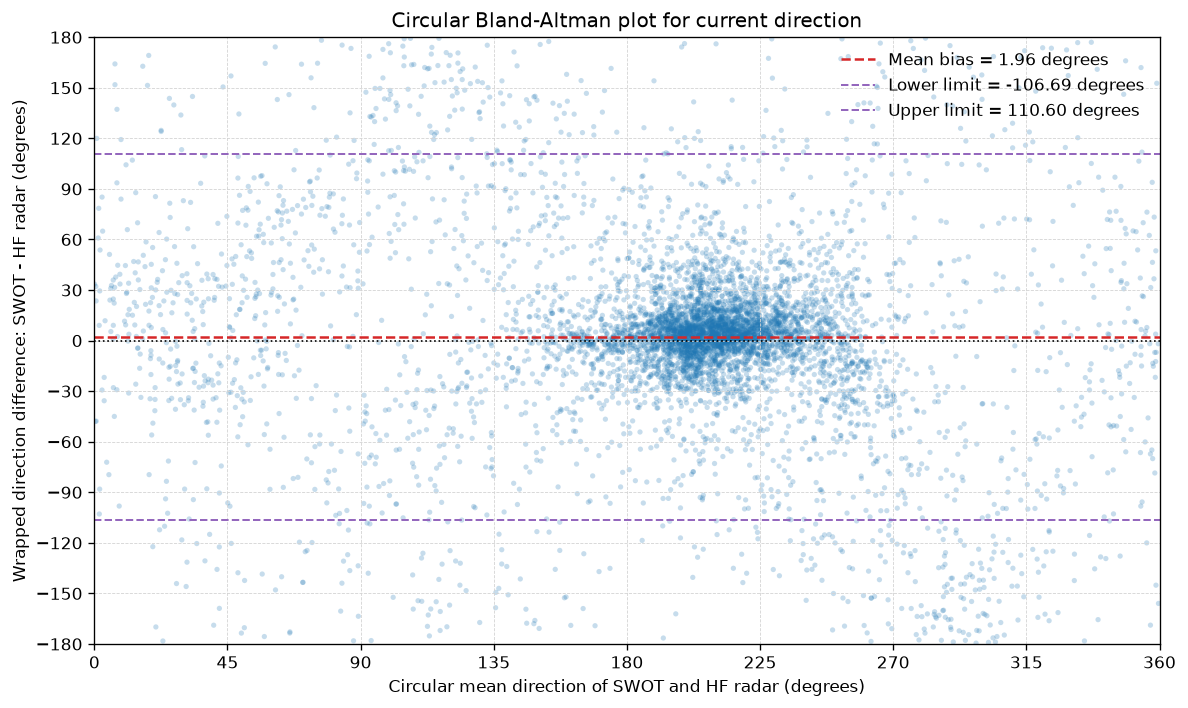

Mean directional bias: 1.96 degrees
95% limits of agreement: -106.69 to 110.60 degrees


In [66]:
data = paired_direction_data['SWOT']

reference_direction = np.radians(data['reference'])
model_direction = np.radians(data['model'])

# Circular mean direction for each SWOT-HF-radar pair.
mean_direction = np.degrees(
    np.arctan2(
        np.sin(reference_direction) + np.sin(model_direction),
        np.cos(reference_direction) + np.cos(model_direction),
    )
) % 360.0

# Wrapped directional difference: SWOT minus HF radar.
direction_difference = wrapped_direction_error(
    data['model'],
    data['reference'],
)

mean_bias = float(np.mean(direction_difference))
difference_sd = float(np.std(direction_difference, ddof=1))
lower_limit = mean_bias - 1.96 * difference_sd
upper_limit = mean_bias + 1.96 * difference_sd

figure, axis = plt.subplots(figsize=(10, 6))

axis.scatter(
    mean_direction,
    direction_difference,
    s=10,
    alpha=0.25,
    color='#1f77b4',
    edgecolors='none',
    rasterized=True,
)

axis.axhline(0, color='black', linestyle=':', linewidth=1)
axis.axhline(
    mean_bias,
    color='#d62728',
    linestyle='--',
    linewidth=1.5,
    label=f'Mean bias = {mean_bias:.2f} degrees',
)
axis.axhline(
    lower_limit,
    color='#9467bd',
    linestyle='--',
    linewidth=1.2,
    label=f'Lower limit = {lower_limit:.2f} degrees',
)
axis.axhline(
    upper_limit,
    color='#9467bd',
    linestyle='--',
    linewidth=1.2,
    label=f'Upper limit = {upper_limit:.2f} degrees',
)

axis.set_xlim(0, 360)
axis.set_ylim(-180, 180)
axis.set_xticks(np.arange(0, 361, 45))
axis.set_yticks(np.arange(-180, 181, 30))
axis.set_xlabel('Circular mean direction of SWOT and HF radar (degrees)')
axis.set_ylabel('Wrapped direction difference: SWOT - HF radar (degrees)')
axis.set_title('Circular Bland-Altman plot for current direction')
axis.legend(frameon=False, loc='upper right')
axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)

figure.tight_layout()
plt.show()

print(f'Mean directional bias: {mean_bias:.2f} degrees')
print(f'95% limits of agreement: {lower_limit:.2f} to {upper_limit:.2f} degrees')

### Directional errors by HF-radar speed bin

Low-speed directions are less stable, so the directional errors are reported separately across HF-radar speed ranges.

In [26]:
data = paired_direction_data['SWOT']
speed_bins = np.array([0.05, 0.25, 0.50, 1.00, 1.50, 2.00, 3.50])
speed_labels = [
    '0.05-0.25',
    '0.25-0.50',
    '0.50-1.00',
    '1.00-1.50',
    '1.50-2.00',
    '2.00-3.50',
]

speed_bin_indices = pd.cut(
    data['reference_speed'],
    bins=speed_bins,
    labels=speed_labels,
    include_lowest=True,
    right=False,
)

speed_bin_rows = []
for label in speed_labels:
    selected = speed_bin_indices == label
    errors = data['error'][selected]
    absolute_errors = data['absolute_error'][selected]
    speed_bin_rows.append({
        'HF-radar speed bin (m/s)': label,
        'n': int(selected.sum()),
        'mean bias (degrees)': float(np.mean(errors)) if errors.size else np.nan,
        'MAE (degrees)': float(np.mean(absolute_errors)) if errors.size else np.nan,
        'RMSE (degrees)': float(np.sqrt(np.mean(errors ** 2))) if errors.size else np.nan,
        'within 30 degrees (%)': float(100 * np.mean(absolute_errors <= 30)) if errors.size else np.nan,
    })

speed_bin_table = pd.DataFrame(speed_bin_rows).set_index('HF-radar speed bin (m/s)')
print(speed_bin_table.round(2).to_string())
speed_bin_table.to_csv(OUTPUT_DIR / 'direction_errors_by_speed_bin.csv')

                             n  mean bias (degrees)  MAE (degrees)  RMSE (degrees)  within 30 degrees (%)
HF-radar speed bin (m/s)                                                                                 
0.05-0.25                 1069                -2.47          72.07           87.17                  25.16
0.25-0.50                 1345                 2.01          53.23           70.74                  42.23
0.50-1.00                 1565                 2.05          29.00           45.66                  70.16
1.00-1.50                 1272                 4.22          14.55           23.86                  89.07
1.50-2.00                  743                 4.06          11.41           18.47                  93.00
2.00-3.50                  222                 2.21           6.85           10.99                  96.40


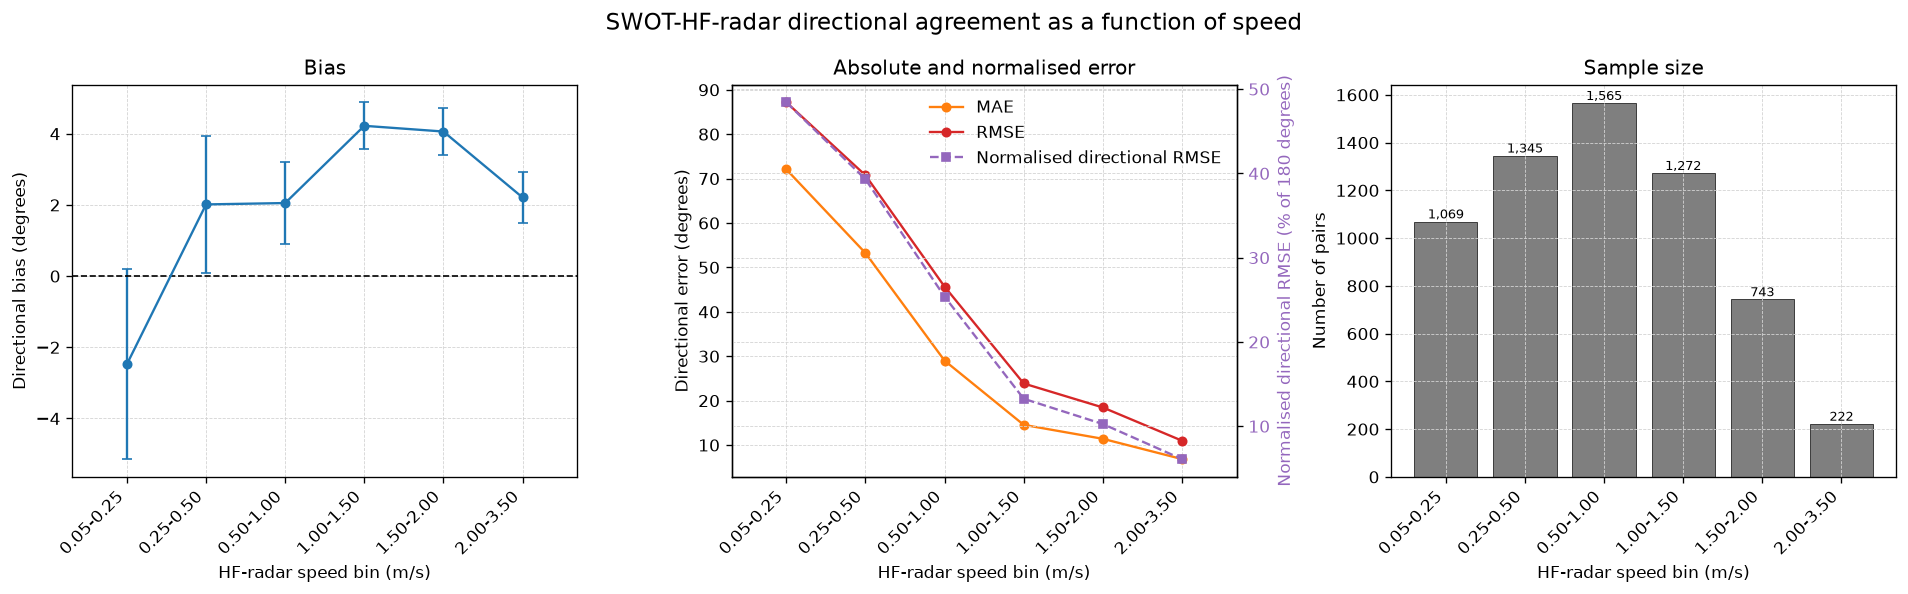

In [ ]:
speed_bin_labels = speed_bin_table.index.to_list()
speed_bin_positions = np.arange(len(speed_bin_labels))

# Estimate the standard error of directional bias within each speed bin.
speed_bin_bias_sem = []
for label in speed_bin_labels:
    selected = speed_bin_indices == label
    errors = data['error'][selected]
    speed_bin_bias_sem.append(
        np.std(errors, ddof=1) / np.sqrt(errors.size)
        if errors.size > 1 else np.nan
    )
speed_bin_bias_sem = np.asarray(speed_bin_bias_sem)

# Directional RMSE as a percentage of the maximum possible wrapped error (180 degrees).
directional_rmse_reference = 180.0
speed_bin_normalised_rmse = (
    100
    * speed_bin_table['RMSE (degrees)'].to_numpy()
    / directional_rmse_reference
)

figure, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)

# Signed directional bias
axes[0].errorbar(
    speed_bin_positions,
    speed_bin_table['mean bias (degrees)'],
    yerr=speed_bin_bias_sem,
    fmt='o-',
    capsize=3,
    color='#1f77b4',
    linewidth=1.4,
    markersize=5,
)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set_title('Bias')
axes[0].set_ylabel('Directional bias (degrees)')
axes[0].set_xlabel('HF-radar speed bin (m/s)')
axes[0].grid(color='lightgrey', linestyle='--', linewidth=0.5)

# Absolute and normalised directional errors
absolute_error_axis = axes[1]
absolute_error_axis.plot(
    speed_bin_positions,
    speed_bin_table['MAE (degrees)'],
    'o-',
    color='#ff7f0e',
    linewidth=1.4,
    markersize=5,
    label='MAE',
)
absolute_error_axis.plot(
    speed_bin_positions,
    speed_bin_table['RMSE (degrees)'],
    'o-',
    color='#d62728',
    linewidth=1.4,
    markersize=5,
    label='RMSE',
)
absolute_error_axis.set_title('Absolute and normalised error')
absolute_error_axis.set_ylabel('Directional error (degrees)')
absolute_error_axis.set_xlabel('HF-radar speed bin (m/s)')
absolute_error_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)

normalised_error_axis = absolute_error_axis.twinx()
normalised_error_axis.plot(
    speed_bin_positions,
    speed_bin_normalised_rmse,
    's--',
    color='#9467bd',
    linewidth=1.4,
    markersize=5,
    label='Normalised directional RMSE',
)
normalised_error_axis.set_ylabel('Normalised directional RMSE (% of 180 degrees)', color='#9467bd')
normalised_error_axis.tick_params(axis='y', labelcolor='#9467bd')

absolute_handles, absolute_labels = absolute_error_axis.get_legend_handles_labels()
normalised_handles, normalised_labels = normalised_error_axis.get_legend_handles_labels()
absolute_error_axis.legend(
    absolute_handles + normalised_handles,
    absolute_labels + normalised_labels,
    frameon=False,
)

# Sample size
axes[2].bar(
    speed_bin_positions,
    speed_bin_table['n'],
    color='#7f7f7f',
    edgecolor='black',
    linewidth=0.4,
)
for bin_position, observation_count in zip(speed_bin_positions, speed_bin_table['n']):
    if observation_count > 0:
        axes[2].text(
            bin_position,
            observation_count,
            f'{observation_count:,}',
            ha='center',
            va='bottom',
            fontsize=8,
        )
axes[2].set_title('Sample size')
axes[2].set_ylabel('Number of pairs')
axes[2].set_xlabel('HF-radar speed bin (m/s)')
axes[2].grid(axis='y', color='lightgrey', linestyle='--', linewidth=0.5)

for axis in axes:
    axis.set_xticks(speed_bin_positions)
    axis.set_xticklabels(speed_bin_labels, rotation=45, ha='right')

figure.tight_layout()
plt.show()

A3. Important Extension: Vector Statistics
The current analysis compares speed magnitude. This can look favourable even when current directions disagree. Add these using the co-located u and v component
- Component-wise bias and RMSE:  uswot - uradar and vswot - vradar
- Vector RMSE: VRMSE = sqrt(mean((us-ur)^2)+(vs-vr)^2)
- Directional error, calculated only above a speed threshold such as 0.05m/s: delta(sigma) = atan2(sin(sigma_s-sigma_r), cos(sigma_s-sigma_r))
- Circular mean directional bias and circular spread.
- Vector RMSE and directional error would be the highest-value next analyses for this dataset.



In [69]:
# Vector RMSE: sqrt(mean((u_SWOT - u_radar)^2 + (v_SWOT - v_radar)^2))

vector_rmse_rows = []

for model_name in model_names:
    squared_vector_errors = []
    pair_count = 0

    for record in records:
        model_u, model_v = record['components'][model_name]
        radar_u, radar_v = record['components']['HF radar']
        model_speed = np.hypot(model_u, model_v)
        radar_speed = np.hypot(radar_u, radar_v)

        valid = (
            record['valid']
            & (model_speed >= MIN_DIRECTION_SPEED)
            & (radar_speed >= MIN_DIRECTION_SPEED)
        )

        delta_u = model_u[valid] - radar_u[valid]
        delta_v = model_v[valid] - radar_v[valid]

        squared_vector_errors.append(delta_u**2 + delta_v**2)
        pair_count += valid.sum()

    vector_rmse = float(np.sqrt(np.mean(np.concatenate(squared_vector_errors))))

    vector_rmse_rows.append({
        'dataset': model_name,
        'vector_rmse_mps': vector_rmse,
        'vector_rmse_n': int(pair_count),
    })

vector_rmse_table = pd.DataFrame(vector_rmse_rows).set_index('dataset')

# Add the vector RMSE to the existing metrics table.
metrics_table = metrics_table.join(vector_rmse_table)

print(metrics_table[['vector_rmse_mps', 'vector_rmse_n']].round(4).to_string())

         vector_rmse_mps  vector_rmse_n
dataset                                
SWOT               0.504           6216


## Interpretation: clustered paired observations

**The 6,216 paired grid-cell comparisons should not be interpreted as 6,216 independent pieces of evidence. They are repeated measurements grouped within the same SWOT overpasses and nearby spatial cells.**

### Why this matters

The notebook treats each valid SWOT-HF-radar grid-cell pair as one observation. That is appropriate for calculating descriptive errors, but it does not mean that every pair provides independent information.

The data structure is closer to:

```text
33 overpasses
├── many nearby grid cells
├── observed at the same time
└── affected by the same regional current conditions
```

Cells from the same overpass are related. Nearby cells may also share similar errors because they experience the same spatial flow structure, radar conditions, and SWOT sampling geometry.

This is a form of **pseudo-replication**: repeated measurements are counted as though they came from independent experiments.

### Effective sample size

If all 6,216 pairs were independent, the nominal sample size would be:

$$
 n_{\mathrm{nominal}} = 6216.
$$

However, because observations are clustered by overpass and spatially correlated, the effective independent sample size is smaller:

$$
 n_{\mathrm{effective}} < 6216.
$$

The exact effective sample size depends on the correlation between observations. As the correlation increases, additional grid cells contribute less new information.

The strongest independent temporal unit is therefore closer to the number of overpasses, approximately 33, than to the number of grid-cell pairs.

### Consequences for interpretation

The clustering affects uncertainty more than the descriptive metric itself:

- The mean bias, MAE, RMSE, and vector RMSE remain useful summaries of the observed paired data.
- Standard errors calculated as if all 6,216 observations were independent would be too small.
- Confidence intervals could be overly narrow.
- Formal significance tests could exaggerate the strength of the result.
- Overpasses with many valid cells may have disproportionate influence on the overall metrics.

Thus, a metric calculated from 6,216 pairs describes the full collection of observed comparisons, but it should not automatically be presented as though it represents 6,216 independent validation experiments.

### Appropriate uncertainty estimation

Uncertainty should be estimated by resampling at the overpass level rather than at the individual-cell level:

```text
resample complete overpasses
        ↓
retain all valid grid-cell pairs within each selected overpass
        ↓
recalculate bias, MAE, RMSE, or vector RMSE
        ↓
repeat many times
```

This preserves the dependence among cells from the same overpass. A block bootstrap could therefore sample the 33 overpasses, with replacement, and calculate confidence intervals from the resulting distribution of metrics.

The same principle applies to directional metrics. Directional pairs from one overpass share the same observation time, SWOT geometry, HF-radar state, and regional flow conditions, so they should be treated as clustered rather than independent.

### Practical conclusion

The existing metrics are suitable as descriptive summaries of the 6,216 observed grid-cell comparisons. Any uncertainty interval, hypothesis test, or claim about statistical significance should instead use an overpass-level or otherwise cluster-aware method.

## Event-level dependence and effective sample size

The grid-cell pairs are clustered within SWOT overpasses. The intraclass correlation coefficient (ICC) estimates how similar errors are within the same overpass relative to the total error variation.

This is an event-level dependence estimate. It captures shared overpass conditions, but it does not fully represent spatial autocorrelation between nearby grid cells.

For a one-way random-effects approximation:

$$
\mathrm{ICC}
=
\frac{MS_{\mathrm{between}}-MS_{\mathrm{within}}}
{MS_{\mathrm{between}}+(\bar{m}-1)MS_{\mathrm{within}}},
$$

where $\bar{m}$ is the mean number of valid observations per overpass. The corresponding design effect and approximate effective sample size are:

$$
\mathrm{design\ effect}=1+(\bar{m}-1)\mathrm{ICC},
$$

$$
 n_{\mathrm{effective}}
=\frac{n_{\mathrm{nominal}}}{\mathrm{design\ effect}}.
$$

In [76]:
# Estimate event-level ICC for speed and directional errors.

def estimate_event_icc(event_values):
    event_values = [values[np.isfinite(values)] for values in event_values]
    event_values = [values for values in event_values if values.size > 1]
    event_count = len(event_values)
    observation_count = sum(values.size for values in event_values)

    if event_count < 2 or observation_count <= event_count:
        return {
            'events': event_count,
            'observations': observation_count,
            'mean_cluster_size': np.nan,
            'icc': np.nan,
            'design_effect': np.nan,
            'effective_n': np.nan,
        }

    cluster_sizes = np.asarray([values.size for values in event_values], dtype=float)
    cluster_means = np.asarray([values.mean() for values in event_values])
    grand_mean = np.concatenate(event_values).mean()
    between_sum_squares = np.sum(cluster_sizes * (cluster_means - grand_mean) ** 2)
    within_sum_squares = sum(
        np.sum((values - cluster_mean) ** 2)
        for values, cluster_mean in zip(event_values, cluster_means)
    )
    mean_square_between = between_sum_squares / (event_count - 1)
    mean_square_within = within_sum_squares / (observation_count - event_count)
    mean_cluster_size = float(cluster_sizes.mean())

    denominator = mean_square_between + (mean_cluster_size - 1) * mean_square_within
    icc = (
        (mean_square_between - mean_square_within) / denominator
        if denominator > 0 else np.nan
    )
    design_effect = 1 + (mean_cluster_size - 1) * max(icc, 0) if np.isfinite(icc) else np.nan
    effective_n = observation_count / design_effect if np.isfinite(design_effect) else np.nan

    return {
        'events': event_count,
        'observations': observation_count,
        'mean_cluster_size': mean_cluster_size,
        'icc': float(icc),
        'design_effect': float(design_effect),
        'effective_n': float(effective_n),
    }

speed_error_by_event = []
direction_error_by_event = []
for record in records:
    coarse_u, coarse_v = record['components']['SWOT']
    radar_u, radar_v = record['components']['HF radar']
    coarse_speed = np.hypot(coarse_u, coarse_v)
    radar_speed = np.hypot(radar_u, radar_v)
    valid = (
        record['valid']
        & (coarse_speed >= MIN_DIRECTION_SPEED)
        & (radar_speed >= MIN_DIRECTION_SPEED)
    )
    speed_error_by_event.append(coarse_speed[valid] - radar_speed[valid])
    coarse_direction = direction_degrees(coarse_u, coarse_v)
    radar_direction = direction_degrees(radar_u, radar_v)
    direction_error_by_event.append(
        wrapped_direction_error(coarse_direction[valid], radar_direction[valid])
    )

speed_icc = estimate_event_icc(speed_error_by_event)
direction_icc = estimate_event_icc(direction_error_by_event)
event_dependence_table = pd.DataFrame(
    [
        {'metric': 'Speed error', **speed_icc},
        {'metric': 'Directional error', **direction_icc},
    ]
).set_index('metric')

print(event_dependence_table.round(3).to_string())

                   events  observations  mean_cluster_size    icc  design_effect  effective_n
metric                                                                                       
Speed error            33          6216            188.364  0.108         21.151      293.886
Directional error      33          6216            188.364  0.043          8.966      693.283


## Interpretation: event-level dependence and effective sample size

**The results show meaningful dependence among grid-cell observations within each overpass, especially for speed errors. Treating all 6,216 pairs as independent would overstate the amount of information.**

### Results

| Error type | ICC | Design effect | Nominal pairs | Approximate effective pairs |
|---|---:|---:|---:|---:|
| Speed error | 0.108 | 21.15 | 6,216 | 294 |
| Directional error | 0.043 | 8.97 | 6,216 | 693 |

The analysis contains 33 overpasses, with approximately 188 valid grid-cell pairs per overpass.

### What the ICC means

The intraclass correlation coefficient measures how similar observations from the same overpass are.

- **Speed-error ICC = 0.108:** approximately 10.8% of the modelled error variation is associated with shared overpass-level conditions.
- **Directional-error ICC = 0.043:** approximately 4.3% is associated with shared overpass-level conditions.

The remaining variation occurs within overpasses, across grid cells. Speed errors are therefore more strongly clustered than directional errors.

### Why the design effect is large

The design effect is approximately:

$$
1 + (\bar{m}-1)\mathrm{ICC},
$$

where $\bar{m}\approx188$ is the mean number of grid-cell pairs per overpass.

For speed error:

$$
1 + (188-1)(0.108) \approx 21.15.
$$

This means that dependence within overpasses reduces the information content of the nominal sample by roughly a factor of 21 for uncertainty calculations.

For directional error:

$$
1 + (188-1)(0.043) \approx 8.97.
$$

The directional observations are less clustered, so their effective sample size is larger.

### What this changes

The descriptive metrics remain valid summaries of the observed data:

- Bias
- MAE
- RMSE
- Vector RMSE
- Directional error statistics

However, uncertainty calculations should not treat all 6,216 pairs as independent. Standard errors based on that assumption would be too small.

The approximate effective sample sizes are therefore:

$$
 n_{\mathrm{eff,speed}} \approx 294,
$$

$$
 n_{\mathrm{eff,direction}} \approx 693.
$$

These are effective information counts, not literal numbers of independent experiments. The strongest independent temporal units remain the 33 overpasses.

### Limitations

This ICC analysis captures shared dependence within overpasses, but it does not fully account for spatial correlation between neighbouring grid cells. The effective sample sizes may therefore still be optimistic.

The most defensible uncertainty method would be an overpass-level block bootstrap:

```text
sample complete overpasses
        ↓
retain all grid-cell pairs within each overpass
        ↓
recalculate the metric
        ↓
repeat many times
```

**Bottom line:** the speed comparison is more strongly clustered than the directional comparison, and both should use overpass-aware uncertainty rather than treating 6,216 grid-cell pairs as independent.